# Delta Air Lines: Flight Delay Prediction

**Applied Machine Learning - Fall 2026**

**Business question:** How can Delta Air Lines use historical flight information to anticipate arrival delays and support proactive operational decision-making?

**Machine learning question:** Using only information available before scheduled departure, how accurately can we predict whether a Delta-operated flight will arrive at least 15 minutes late, and which pre-departure flight characteristics are most predictive of delay risk?

**Scope:** U.S. BTS Reporting Carrier On-Time Performance records for 2025. We predict `ARR_DEL15` for completed flights with observed arrival outcomes. 

**Prediction timing:** Before scheduled departure. Actual departure/arrival outcomes must never be predictors.

This notebook documents the data processing and modelling workflow. All findings should be based on the actual output generated below.


#LAD OS KIGGE PÅ DENNE START IGEN INDEN VI AFLEVERER, HVIS DER SKAL TILFØJES NOGET ELLER MANGLER NOGET

## 1. Import libraries and configure paths

Here we run Jupyter from the repository root, where `flight_delay_analysis.ipynb` and `data/` are next to each other.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
MONTHLY_FILES = [DATA_DIR / f"{month:02d}-2025.csv" for month in range(1, 13)]

missing_files = [str(path) for path in MONTHLY_FILES if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing BTS monthly file(s): {missing_files}")

print(f"Found all {len(MONTHLY_FILES)} monthly files.")

Found all 12 monthly files.


## 2. Data collection

We downloaded the 2025 flight data from BTS as twelve monthly files and stacked them on top of each other into one dataset. While loading each file, we check that all the columns we need are there, and that the file only contains flights from the right month. To keep the dataset small, we only keep flights operated by Delta (DL). We also save how many flights each month had in total and how many were Delta, so we can document how the dataset was built.

This is described in Section 2.1 of the report.

In [17]:
# the 11 columns we need, grouped in 4 categories
EXPECTED_COLUMNS = [
    # Flight Information
    "FL_DATE", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST",
    # Schedule
    "CRS_DEP_TIME", "CRS_ARR_TIME", "CRS_ELAPSED_TIME", "DISTANCE",
    # Flight Status
    "CANCELLED", "DIVERTED",
    # Outcome (target)
    "ARR_DEL15",
]

# an empty list where we save the Delta flights from each month
monthly_delta = []

# going through the 12 monthly files one by one
for file_path in MONTHLY_FILES:
    # reading only the 11 columns we need
    monthly = pd.read_csv(file_path, usecols=EXPECTED_COLUMNS)

    # keeping only flights operated by Delta (DL)
    delta = monthly[monthly["OP_UNIQUE_CARRIER"] == "DL"]

    # showing how many flights the file had, and how many were Delta
    print(file_path.name, "- all flights:", len(monthly), "- Delta flights:", len(delta))

    # saving the Delta flights in the list
    monthly_delta.append(delta)

# stacking the 12 months on top of each other into one table
df = pd.concat(monthly_delta, ignore_index=True)

# turn FL_DATE from text into a real date, so we can get the month and weekday later
df["FL_DATE"] = pd.to_datetime(df["FL_DATE"], format="%m/%d/%Y %I:%M:%S %p")

# show the total number of Delta flights in 2025
print("Total Delta flights in 2025:", len(df))

# check that we have flights from all 12 months (1 = January, 12 = December)
df["FL_DATE"].dt.month.value_counts().sort_index()

01-2025.csv - all flights: 539747 - Delta flights: 76306
02-2025.csv - all flights: 504884 - Delta flights: 71333
03-2025.csv - all flights: 600872 - Delta flights: 84487
04-2025.csv - all flights: 583950 - Delta flights: 84188
05-2025.csv - all flights: 605648 - Delta flights: 89931
06-2025.csv - all flights: 611575 - Delta flights: 91122
07-2025.csv - all flights: 631428 - Delta flights: 94066
08-2025.csv - all flights: 602378 - Delta flights: 90313
09-2025.csv - all flights: 562439 - Delta flights: 84875
10-2025.csv - all flights: 605844 - Delta flights: 90097
11-2025.csv - all flights: 570550 - Delta flights: 84475
12-2025.csv - all flights: 582304 - Delta flights: 85139
Total Delta flights in 2025: 1026332


FL_DATE
1     76306
2     71333
3     84487
4     84188
5     89931
6     91122
7     94066
8     90313
9     84875
10    90097
11    84475
12    85139
Name: count, dtype: int64

## 3. Getting to know the data (EDA) & data quality

**The main idea (from Session 2):** before we clean the data, we first find the problems. In this section we only **look** at the data. We do not change anything yet.

**The plan:**
1. EDA – How big is the data, and what type of data is in each column?
2. Check 1 – Does each column look normal on its own?
3. Check 2 – Do the columns make sense together?
4. Check 3 – Does the data follow the rules?
5. Check 4 – What is missing, and why?
6. Summary – the 7 data quality dimensions

 **Step 1**

In [21]:
# ===== EDA: size and data types =====
# show the first 5 rows, to check that the data was read in correctly
display(df.head(5))

# number of rows (flights) and columns
print("--- Size ---")
print("Rows (flights):", df.shape[0])
print("Columns:", df.shape[1])

# first and last date, number of different dates and airports
print("\n--- Dates and airports ---")
print("Date range:", df["FL_DATE"].min().date(), "to", df["FL_DATE"].max().date())
print("Unique dates:", df["FL_DATE"].nunique())
print("Unique origin airports:", df["ORIGIN"].nunique())
print("Unique destination airports:", df["DEST"].nunique())

# column names, how many cells are filled in, and the data type of each column
print("\n--- Data types ---")
df.info()

,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
0,2025-01-01,DL,ABQ,ATL,635,1132,0.0,0.0,0.0,177.0,1269.0
1,2025-01-01,DL,ABQ,ATL,1135,1633,0.0,0.0,0.0,178.0,1269.0
2,2025-01-01,DL,ABQ,MSP,800,1139,0.0,0.0,0.0,159.0,981.0
3,2025-01-01,DL,ALB,ATL,605,859,0.0,0.0,0.0,174.0,853.0
4,2025-01-01,DL,ALB,ATL,1413,1705,0.0,0.0,0.0,172.0,853.0


--- Size ---
Rows (flights): 1026332
Columns: 11

--- Dates and airports ---
Date range: 2025-01-01 to 2025-12-31
Unique dates: 365
Unique origin airports: 153
Unique destination airports: 153

--- Data types ---
<class 'pandas.DataFrame'>
RangeIndex: 1026332 entries, 0 to 1026331
Data columns (total 11 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   FL_DATE            1026332 non-null  datetime64[us]
 1   OP_UNIQUE_CARRIER  1026332 non-null  str           
 2   ORIGIN             1026332 non-null  str           
 3   DEST               1026332 non-null  str           
 4   CRS_DEP_TIME       1026332 non-null  int64         
 5   CRS_ARR_TIME       1026332 non-null  int64         
 6   ARR_DEL15          1012427 non-null  float64       
 7   CANCELLED          1026332 non-null  float64       
 8   DIVERTED           1026332 non-null  float64       
 9   CRS_ELAPSED_TIME   1026332 non-null  float64       
 

**Step 2 - Check 1: Does each column look normal on its own? (Univariate analysis)**

,DISTANCE,CRS_ELAPSED_TIME
count,1.026332e+06,1.026332e+06
mean,9.588129e+02,1.614236e+02
std,6.534858e+02,7.989110e+01
min,9.500000e+01,4.400000e+01
25%,4.810000e+02,1.010000e+02
50%,7.610000e+02,1.390000e+02
75%,1.276000e+03,2.020000e+02
max,5.095000e+03,7.390000e+02


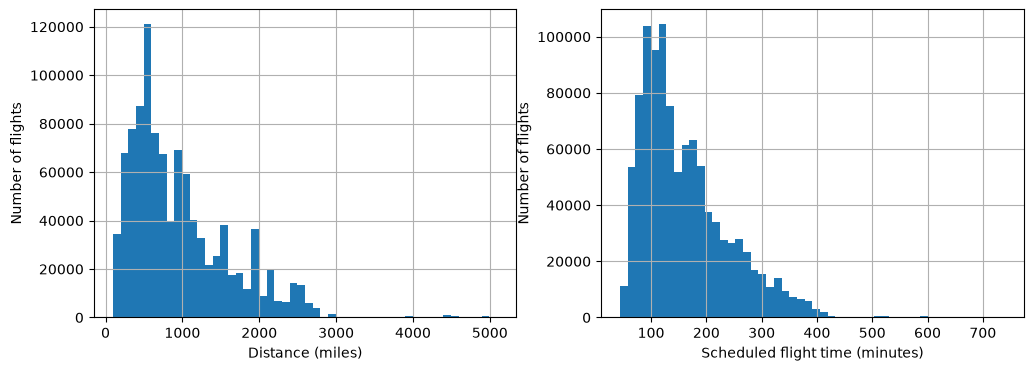

ARR_DEL15
0.0    0.802
1.0    0.198
Name: proportion, dtype: float64


In [22]:
# smallest, largest and average value of the numbers we care about
display(df[["DISTANCE", "CRS_ELAPSED_TIME"]].describe())

# histograms of distance and scheduled flight time, side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["DISTANCE"].hist(bins=50, ax=axes[0])
axes[0].set(xlabel="Distance (miles)", ylabel="Number of flights")
df["CRS_ELAPSED_TIME"].hist(bins=50, ax=axes[1])
axes[1].set(xlabel="Scheduled flight time (minutes)", ylabel="Number of flights")
plt.show()

# share of on-time (0) and late (1) flights (value_counts skips empty cells by itself)
print(df["ARR_DEL15"].value_counts(normalize=True).round(3))

**Findings - Step 2:**
- **All values look realistic.** Distance goes from 95 to 5,095 miles, and flight time from 44 to 739 minutes. No zeros or negative values.
- **Target:** 80.2% of the flights are on time and **19.8% are late**. This is **unbalanced data**, so accuracy alone can trick us. We will also use precision, recall and F1.

**Step 3 - Check 2: Do the columns make sense together? (Bivariate and Multivariate analysis)**

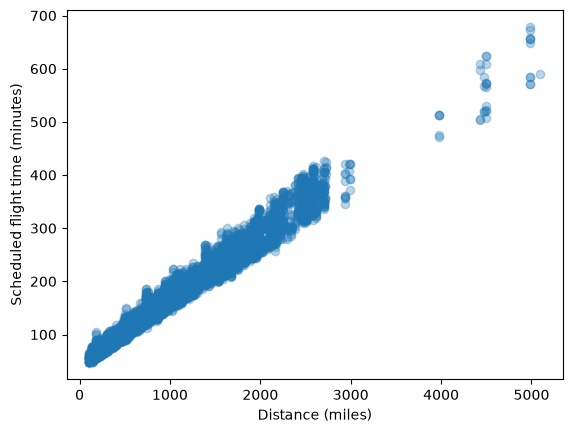

Correlation: 0.98
Strange flights: 0


In [23]:
# 10,000 random flights: distance vs. scheduled flight time
sample = df.sample(10000, random_state=1)
plt.scatter(sample["DISTANCE"], sample["CRS_ELAPSED_TIME"], alpha=0.3)
plt.xlabel("Distance (miles)")
plt.ylabel("Scheduled flight time (minutes)")
plt.show()

# correlation: 1 = perfect, 0 = no connection
print("Correlation:", round(df["DISTANCE"].corr(df["CRS_ELAPSED_TIME"]), 2))

# strange flights: over 1,500 miles but under 60 minutes (0 = none)
strange = df[(df["DISTANCE"] > 1500) & (df["CRS_ELAPSED_TIME"] < 60)]
print("Strange flights:", len(strange))

**Findings - Step 3:**
- Distance and flight time fit together: the longer the flight, the longer it takes (correlation 0.98).
- There are no strange flights, such as a long distance with a very short flight time.


**Step 4 - Check 3: Does the data follow the rules? (Constraint and rule checking)**

In [24]:
# True = all flights follow the rule, False = some flights break it
# % 100 gives the last two digits of the time (the minutes)
rules = {
    "ARR_DEL15 is only 0 or 1": df["ARR_DEL15"].dropna().isin([0, 1]).all(),
    "CANCELLED is only 0 or 1": df["CANCELLED"].isin([0, 1]).all(),
    "DIVERTED is only 0 or 1": df["DIVERTED"].isin([0, 1]).all(),
    "All flights are from 2025": (df["FL_DATE"].dt.year == 2025).all(),
    "CRS_DEP_TIME is 0-2359": df["CRS_DEP_TIME"].between(0, 2359).all(),
    "CRS_DEP_TIME minutes < 60": (df["CRS_DEP_TIME"] % 100 < 60).all(),
    "CRS_ARR_TIME is 0-2359": df["CRS_ARR_TIME"].between(0, 2359).all(),
    "CRS_ARR_TIME minutes < 60": (df["CRS_ARR_TIME"] % 100 < 60).all(),
    "DISTANCE is above 0": (df["DISTANCE"] > 0).all(),
    "CRS_ELAPSED_TIME is above 0": (df["CRS_ELAPSED_TIME"] > 0).all(),
    "ORIGIN and DEST are different": (df["ORIGIN"] != df["DEST"]).all(),
    "No duplicate rows": not df.duplicated().any(),
}

for rule, ok in rules.items():
    print(ok, "-", rule)

True - ARR_DEL15 is only 0 or 1
True - CANCELLED is only 0 or 1
True - DIVERTED is only 0 or 1
True - All flights are from 2025
True - CRS_DEP_TIME is 0-2359
True - CRS_DEP_TIME minutes < 60
True - CRS_ARR_TIME is 0-2359
True - CRS_ARR_TIME minutes < 60
True - DISTANCE is above 0
True - CRS_ELAPSED_TIME is above 0
True - ORIGIN and DEST are different
True - No duplicate rows


**Findings - Step 4:**
We made a list of rules that must always be true, for example:
- yes/no columns can only be 0 or 1
- times must be real clock times (00:00–23:59)
- distance and flight time must be above 0
- a flight can't land at the same airport it left from
- the same flight can't appear twice

All rules were **True**, so no flight breaks any rule. We found **no impossible values** in the data.

**Step 5 - Check 4: What is missing, and why? (Missingness analysis)**

In [25]:
# number of empty cells in each column
print(df.isna().sum())
print()

# are the flights with an empty target cancelled or diverted?
missing = df[df["ARR_DEL15"].isna()]
print("Flights with empty target:", len(missing))
print("Of these, cancelled:", int(missing["CANCELLED"].sum()))
print("Of these, diverted:", int(missing["DIVERTED"].sum()))

# share of flights with an empty target for each month (0.03 = 3%)
print()
print("Share of empty targets per month:")
print(df["ARR_DEL15"].isna().groupby(df["FL_DATE"].dt.month).mean().round(3))

FL_DATE                  0
OP_UNIQUE_CARRIER        0
ORIGIN                   0
DEST                     0
CRS_DEP_TIME             0
CRS_ARR_TIME             0
ARR_DEL15            13905
CANCELLED                0
DIVERTED                 0
CRS_ELAPSED_TIME         0
DISTANCE                 0
dtype: int64

Flights with empty target: 13905
Of these, cancelled: 11114
Of these, diverted: 2791

Share of empty targets per month:
FL_DATE
1     0.030
2     0.004
3     0.007
4     0.007
5     0.005
6     0.022
7     0.019
8     0.011
9     0.003
10    0.005
11    0.019
12    0.030
Name: ARR_DEL15, dtype: float64


**Findings - Step 5:**

**1. How much is missing?:** Only the target ARR_DEL15: 13,905 flights.

**2. Who is missing?:** All of them are cancelled (11,114) or diverted (2,791) flights. They are most common in January and December (3%) and rare in February and September (under 0.5%).

**3. Which type is it?:** = **MAR.** There is a clear pattern, and we can see the reason in other columns (CANCELLED, DIVERTED and the month). It is not MCAR (not random) and not MNAR (the reason is not hidden).

**4. What do we do?:** We **remove** these flights in the next section **(SECTION XXX??X?X)**. The reason for removing them is due to for example filling in the average (about 0.2) makes no sense, because a flight can't be "0.2 late", and a cancelled flight never arrived.

**5. How could it affect our results?:** Cancellations are most common in busy winter and holiday months. Removing them may make the data look slightly calmer than reality, and the model cannot predict cancellations.

## VI SKAL FINDE UD AF OM VI SKAL BRUGE KODEN FORNEDEN HER

In [16]:
display(df.head())
print("Shape:", df.shape)
print("Date range:", df["FL_DATE"].min(), "to", df["FL_DATE"].max())
print("Unique dates:", df["FL_DATE"].nunique())
print("Unique origin airports:", df["ORIGIN"].nunique())
print("Unique destination airports:", df["DEST"].nunique())

missingness = (
    df.isna().sum().rename("missing_count").to_frame()
    .assign(missing_pct=lambda x: 100 * x["missing_count"] / len(df))
    .sort_values("missing_count", ascending=False)
)
display(missingness)

print("Cancelled:", int((df["CANCELLED"] == 1).sum()))
print("Diverted:", int((df["DIVERTED"] == 1).sum()))
print("Missing arrival target:", int(df["ARR_DEL15"].isna().sum()))
print("Exact duplicate rows (review before removing):", int(df.duplicated().sum()))

,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
0,2025-01-01,DL,ABQ,ATL,635,1132,0.0,0.0,0.0,177.0,1269.0
1,2025-01-01,DL,ABQ,ATL,1135,1633,0.0,0.0,0.0,178.0,1269.0
2,2025-01-01,DL,ABQ,MSP,800,1139,0.0,0.0,0.0,159.0,981.0
3,2025-01-01,DL,ALB,ATL,605,859,0.0,0.0,0.0,174.0,853.0
4,2025-01-01,DL,ALB,ATL,1413,1705,0.0,0.0,0.0,172.0,853.0


Shape: (1026332, 11)
Date range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00
Unique dates: 365
Unique origin airports: 153
Unique destination airports: 153


,missing_count,missing_pct
ARR_DEL15,13905,1.354825
FL_DATE,0,0.000000
OP_UNIQUE_CARRIER,0,0.000000
ORIGIN,0,0.000000
DEST,0,0.000000
CRS_DEP_TIME,0,0.000000
CRS_ARR_TIME,0,0.000000
CANCELLED,0,0.000000
DIVERTED,0,0.000000
CRS_ELAPSED_TIME,0,0.000000


Cancelled: 11114
Diverted: 2791
Missing arrival target: 13905
Exact duplicate rows (review before removing): 0


## ALT FORNEDEN SKAL JOSE OG MALOU LIGE VURDERER OM DET SPILLER SAMMEN MED DET FOR OVEN


## 4. Define the modelling population

The target is defined only for completed flights with a known outcome. We exclude cancelled or diverted flights and observations with missing `ARR_DEL15`. We do **not** replace missing target values with 0. Note that this limits the scope: the model does not predict cancellations or diversions.

In [6]:
valid_status = (df["CANCELLED"] == 0) & (df["DIVERTED"] == 0)
valid_target = df["ARR_DEL15"].isin([0, 1])
clean = df.loc[valid_status & valid_target].copy()
clean["ARR_DEL15"] = clean["ARR_DEL15"].astype(int)

print(f"Before cleaning: {len(df):,} Delta flights")
print(f"After cleaning:  {len(clean):,} completed flights with known target")
print(f"Excluded:        {len(df) - len(clean):,} rows")
print(f"Arrival delay rate: {clean['ARR_DEL15'].mean():.2%}")
display(clean["ARR_DEL15"].value_counts().rename(index={0: "On time (<15 min late)", 1: "Delayed (>=15 min late)"}).to_frame("flights"))

Before cleaning: 1,026,332 Delta flights
After cleaning:  1,012,427 completed flights with known target
Excluded:        13,905 rows
Arrival delay rate: 19.79%


,flights
ARR_DEL15,
On time (<15 min late),812025
Delayed (>=15 min late),200402


## 5. Exploratory data analysis (EDA)

**Descriptive questions:** What fraction of flights arrived 15+ minutes late? Does delay incidence differ by month, weekday, scheduled departure hour, or origin airport? These are descriptive associations, not causal effects. Seasonal results will inform the discussion of 2025 representativeness and evaluation design.

,flights,delay_rate,delay_rate_pct
MONTH,,,
1,74025,0.193205,19.320500
2,71061,0.199702,19.970166
3,83857,0.184206,18.420645
4,83560,0.177705,17.770464
5,89472,0.220114,22.011356
6,89155,0.261702,26.170153
7,92245,0.248447,24.844707
8,89322,0.170260,17.026041
9,84630,0.123845,12.384497


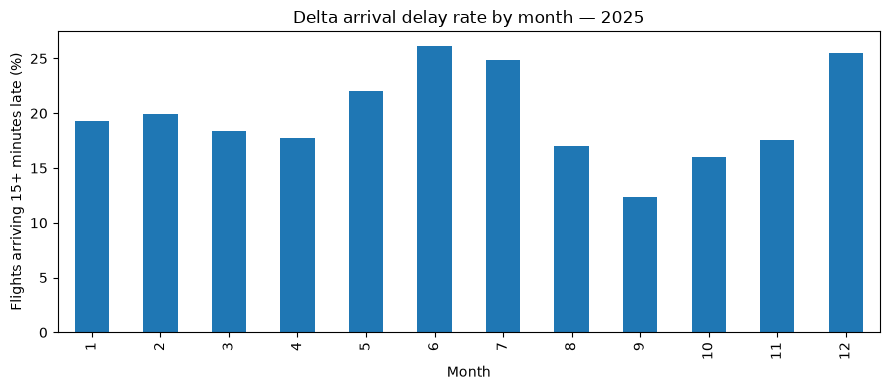

In [7]:
clean["MONTH"] = clean["FL_DATE"].dt.month
clean["DAY_OF_WEEK"] = clean["FL_DATE"].dt.dayofweek + 1  # Monday=1, Sunday=7

# CRS_DEP_TIME is stored as a four-digit local HHMM scheduled clock time.
clean["DEP_HOUR"] = pd.to_numeric(clean["CRS_DEP_TIME"], errors="coerce") // 100
clean.loc[~clean["DEP_HOUR"].between(0, 23), "DEP_HOUR"] = np.nan

monthly = (clean.groupby("MONTH")["ARR_DEL15"]
           .agg(flights="size", delay_rate="mean")
           .reindex(range(1, 13)))
monthly["delay_rate_pct"] = 100 * monthly["delay_rate"]
display(monthly)

fig, ax = plt.subplots(figsize=(9, 4))
monthly["delay_rate_pct"].plot(kind="bar", ax=ax)
ax.set(title="Delta arrival delay rate by month — 2025",
       xlabel="Month", ylabel="Flights arriving 15+ minutes late (%)")
plt.tight_layout()
plt.show()

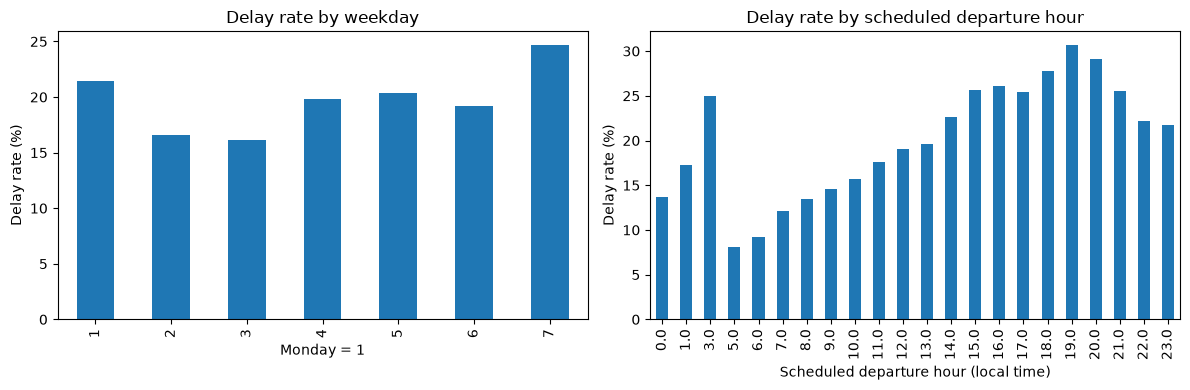

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

weekday = clean.groupby("DAY_OF_WEEK")["ARR_DEL15"].mean().mul(100)
weekday.plot(kind="bar", ax=axes[0])
axes[0].set(title="Delay rate by weekday", xlabel="Monday = 1", ylabel="Delay rate (%)")

hourly = clean.groupby("DEP_HOUR")["ARR_DEL15"].mean().mul(100)
hourly.plot(kind="bar", ax=axes[1])
axes[1].set(title="Delay rate by scheduled departure hour",
            xlabel="Scheduled departure hour (local time)", ylabel="Delay rate (%)")

plt.tight_layout()
plt.show()

In [9]:
origin_summary = (clean.groupby("ORIGIN")["ARR_DEL15"]
                  .agg(flights="size", delay_rate="mean"))
origin_summary = origin_summary.loc[origin_summary["flights"] >= 1000]
origin_summary = origin_summary.sort_values("delay_rate", ascending=False)
origin_summary["delay_rate_pct"] = 100 * origin_summary["delay_rate"]
print("Origin airports with >=1,000 completed Delta flights in 2025")
display(origin_summary.head(10))

Origin airports with >=1,000 completed Delta flights in 2025


,flights,delay_rate,delay_rate_pct
ORIGIN,,,
EWR,6414,0.291082,29.108201
MIA,11017,0.272942,27.294182
LGA,28462,0.270993,27.099290
ORD,10875,0.260966,26.096552
BOS,25511,0.241504,24.150367
MCO,20548,0.238807,23.880670
FLL,12360,0.237540,23.754045
PBI,7061,0.234669,23.466931
ROC,1022,0.232877,23.287671


### EDA findings — complete after running the code

Document only what the actual results show:

- **Sample size:** [insert number of completed Delta flights]
- **Overall delay rate:** [insert %]
- **Seasonality:** [describe high/low months and whether the differences are substantial]
- **Scheduled departure hour / airports:** [describe relevant patterns]
- **Important caveat:** One calendar year may reflect unusual year-specific conditions; monthly variation does not by itself prove the patterns recur in future years.

Do not assume summer or December has the highest delay rate before examining the data.

## 6. Feature selection and leakage audit

Predictors must be available **before scheduled departure**.

| Role | Variables | Notes |
| --- | --- | --- |
| Target | `ARR_DEL15` | Binary observed arrival outcome |
| Candidate predictors | `ORIGIN`, `DEST`, `CRS_DEP_TIME`, `CRS_ARR_TIME`, `CRS_ELAPSED_TIME`, `DISTANCE`, `MONTH`, `DAY_OF_WEEK` | Derived calendar features are based on `FL_DATE` |
| Filtering only | `OP_UNIQUE_CARRIER`, `CANCELLED`, `DIVERTED` | Not predictors in the first modelling setup |
| Date for splitting | `FL_DATE` | Preserve date for possible temporal evaluation |

**Important:** Actual arrival/departure times, actual delays, and post-departure causes are excluded. `CRS_DEP_TIME` and `CRS_ARR_TIME` are local clock times; do not subtract them to estimate duration across time zones. Use `CRS_ELAPSED_TIME` instead.

**Target population caveat:** At deployment time, whether a flight will ultimately be cancelled or diverted is unknown. This model estimates delay risk conditional on the completed-flight population used for training; discuss this scope limitation in the report.

In [10]:
FEATURES = [
    "ORIGIN", "DEST", "CRS_DEP_TIME", "CRS_ARR_TIME",
    "CRS_ELAPSED_TIME", "DISTANCE", "MONTH", "DAY_OF_WEEK"
]
TARGET = "ARR_DEL15"

print("Candidate features:", FEATURES)
print("Any missing feature values?")
display(clean[FEATURES].isna().sum().to_frame("missing_count"))

Candidate features: ['ORIGIN', 'DEST', 'CRS_DEP_TIME', 'CRS_ARR_TIME', 'CRS_ELAPSED_TIME', 'DISTANCE', 'MONTH', 'DAY_OF_WEEK']
Any missing feature values?


,missing_count
ORIGIN,0
DEST,0
CRS_DEP_TIME,0
CRS_ARR_TIME,0
CRS_ELAPSED_TIME,0
DISTANCE,0
MONTH,0
DAY_OF_WEEK,0


## 7. Next steps: split, preprocessing, modelling and evaluation

**Do not train models on the full dataset yet.** First agree on the evaluation target:

1. A random stratified split estimates performance on similar within-2025 observations but can be optimistic when nearby flights share unobserved disruptions.
2. A chronological split better resembles prediction on later periods, but one year's earlier months do not include a complete seasonal cycle.
3. Decide on a primary evaluation and, if feasible, a separate temporal robustness check. Keep final test data untouched while tuning.
4. Fit imputers, encoders and scalers **only on the training portion**, preferably using scikit-learn `Pipeline`/`ColumnTransformer`.
5. Start with a `DummyClassifier` and Logistic Regression. Add Decision Tree and/or Random Forest if useful.
6. Evaluate precision, recall, F1, ROC-AUC, confusion matrix, errors by subgroup and practical business implications.

**Write-up:** The notebook shows all code, checks, results and brief interpretation; the report focuses on the key design decisions, outcomes and limitations.